	解释选定模型的全局与局部预测

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import shap

model_dir = Path("reports/morgan_random_forest")

model = joblib.load(model_dir / "additive_model.joblib")

with (model_dir / "additive_config.json").open(
    encoding="utf-8"
) as file:
    config = json.load(file)

test_predictions = pd.read_csv(
    model_dir / "additive_test_predictions.csv",
    index_col="source_row_index",
)

print("SHAP version:", shap.__version__)
print("Model type:", type(model).__name__)
print("Model feature count:", model.n_features_in_)
print("Test records:", len(test_predictions))
print("Role order:", config["roles"])
print("Fingerprint settings:", config["fingerprint"])

c:\Users\eric_lu\Documents\ChatGPT\ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1
Model type: RandomForestRegressor
Model feature count: 8192
Test records: 180
Role order: ['Aryl halide', 'Ligand', 'Base', 'Additive']
Fingerprint settings: {'type': 'Morgan', 'radius': 2, 'fpSize': 2048, 'includeChirality': True}


In [2]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

roles = config["roles"]
fp_settings = config["fingerprint"]

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=fp_settings["radius"],
    fpSize=fp_settings["fpSize"],
    includeChirality=fp_settings["includeChirality"],
)

unique_smiles = pd.unique(
    test_predictions[roles].to_numpy().ravel()
)
fingerprint_arrays = {}

for smiles in unique_smiles:
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    fingerprint_arrays[smiles] = np.array(
        list(generator.GetFingerprint(molecule)),
        dtype=np.uint8,
    )

blocks = [
    np.stack([
        fingerprint_arrays[smiles]
        for smiles in test_predictions[role]
    ])
    for role in roles
]

X_test = pd.DataFrame(
    np.concatenate(blocks, axis=1),
    index=test_predictions.index,
)

rebuilt_predictions = model.predict(X_test)
saved_predictions = test_predictions["predicted_yield"].to_numpy()

assert X_test.shape[1] == model.n_features_in_
assert np.allclose(
    rebuilt_predictions, saved_predictions,
    rtol=0, atol=1e-6,
)

print("Test feature shape:", X_test.shape)
print(
    "Maximum prediction difference:",
    np.max(np.abs(rebuilt_predictions - saved_predictions)),
)
print("Rebuilt predictions match the saved predictions.")

Test feature shape: (180, 8192)
Maximum prediction difference: 4.263256414560601e-14
Rebuilt predictions match the saved predictions.


In [3]:
X_preview = X_test.iloc[:5]

explainer = shap.TreeExplainer(
    model,
    feature_perturbation="tree_path_dependent",
    model_output="raw",
)

preview_shap = explainer(X_preview)

shap_reconstructed = (
    preview_shap.base_values
    + preview_shap.values.sum(axis=1)
)
direct_predictions = model.predict(X_preview)

assert np.allclose(
    shap_reconstructed, direct_predictions,
    rtol=0, atol=1e-5,
)

check_table = pd.DataFrame({
    "observed_yield": test_predictions.loc[X_preview.index, "Output"],
    "model_prediction": direct_predictions,
    "shap_base_value": preview_shap.base_values,
    "total_shap_contribution": preview_shap.values.sum(axis=1),
    "reconstructed_prediction": shap_reconstructed,
})

display(check_table.round(3))
print("SHAP contributions reconstruct the model predictions.")

,observed_yield,model_prediction,shap_base_value,total_shap_contribution,reconstructed_prediction
source_row_index,,,,,
42,97.568,84.886,33.165,51.720,84.886
68,2.345,4.690,33.165,-28.476,4.690
80,51.813,48.244,33.165,15.078,48.244
100,29.298,28.915,33.165,-4.251,28.915
144,7.802,7.720,33.165,-25.446,7.720


SHAP contributions reconstruct the model predictions.


SHAP value shape: (180, 8192)
All test predictions reconstructed successfully.


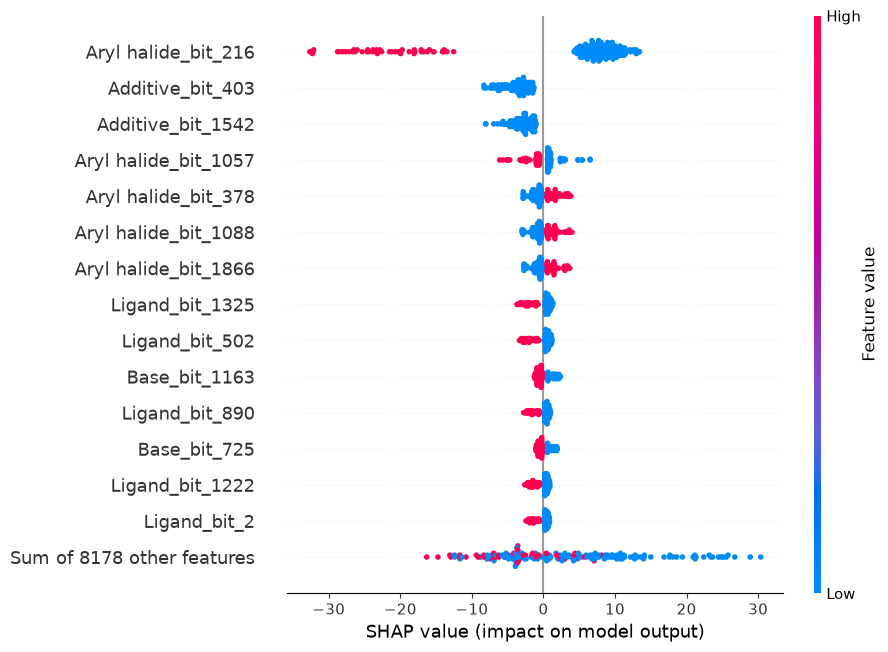

In [4]:
import matplotlib.pyplot as plt

feature_names = [
    f"{role}_bit_{bit}"
    for role in roles
    for bit in range(fp_settings["fpSize"])
]

shap_values = explainer(X_test)
shap_values.feature_names = feature_names

assert np.allclose(
    shap_values.base_values + shap_values.values.sum(axis=1),
    rebuilt_predictions,
    rtol=0,
    atol=1e-5,
)

print("SHAP value shape:", shap_values.values.shape)
print("All test predictions reconstructed successfully.")

shap.plots.beeswarm(shap_values, max_display=15)

,Mean absolute role contribution
Aryl halide,14.771150
Ligand,7.479670
Base,5.377270
Additive,3.335268


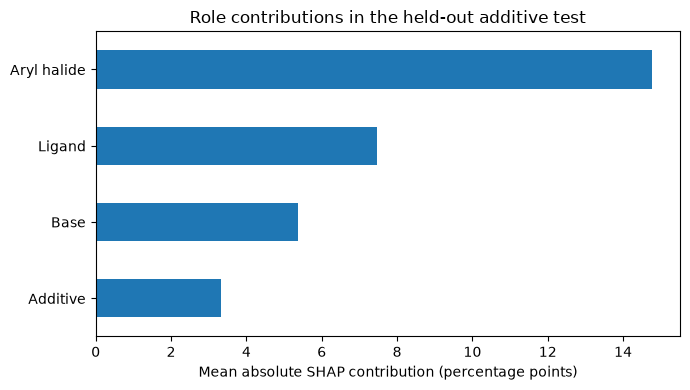

In [5]:
bits_per_role = fp_settings["fpSize"]

role_contributions = pd.DataFrame(
    {
        role: shap_values.values[
            :, i * bits_per_role:(i + 1) * bits_per_role
        ].sum(axis=1)
        for i, role in enumerate(roles)
    },
    index=X_test.index,
)

assert np.allclose(
    shap_values.base_values + role_contributions.sum(axis=1),
    rebuilt_predictions,
    rtol=0,
    atol=1e-5,
)

role_importance = (
    role_contributions.abs()
    .mean()
    .sort_values(ascending=False)
)

display(role_importance.rename("Mean absolute role contribution").to_frame())

role_fig, ax = plt.subplots(figsize=(7, 4))
role_importance.sort_values().plot.barh(ax=ax)

ax.set(
    title="Role contributions in the held-out additive test",
    xlabel="Mean absolute SHAP contribution (percentage points)",
    ylabel="",
)

role_fig.tight_layout()
plt.show()


Low-error case | Source row: 3552
Observed yield: 0.34%
Predicted yield: 0.34%
Absolute error: 0.00 percentage points


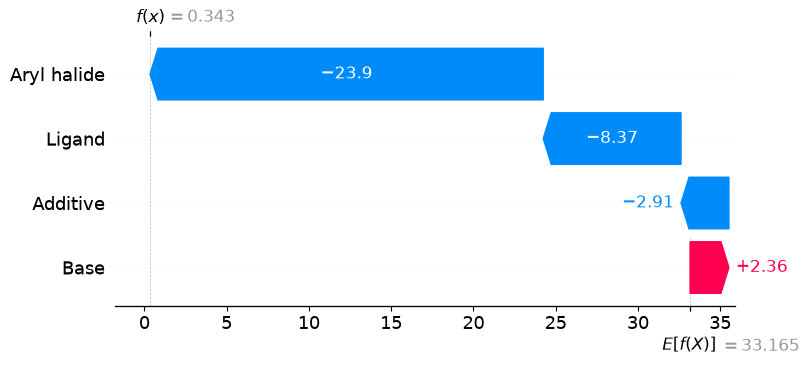


High-error case | Source row: 2293
Observed yield: 86.42%
Predicted yield: 42.23%
Absolute error: 44.19 percentage points


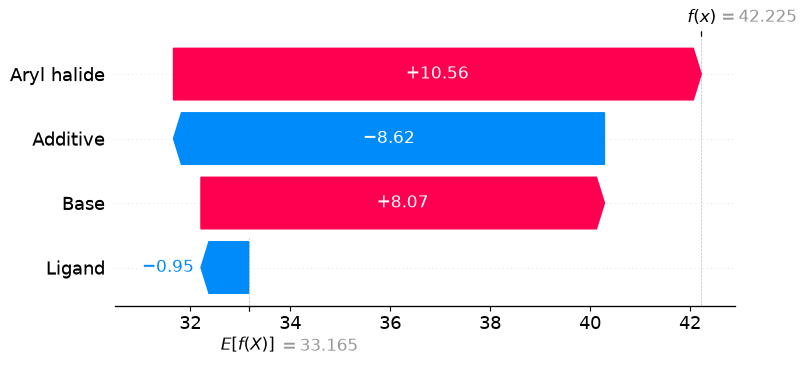

In [6]:
absolute_errors = (
    test_predictions["Output"] - test_predictions["predicted_yield"]
).abs()

case_ids = {
    "Low-error case": absolute_errors.idxmin(),
    "High-error case": absolute_errors.idxmax(),
}

for label, row_id in case_ids.items():
    position = X_test.index.get_loc(row_id)

    print(f"\n{label} | Source row: {row_id}")
    print(f"Observed yield: {test_predictions.loc[row_id, 'Output']:.2f}%")
    print(f"Predicted yield: {rebuilt_predictions[position]:.2f}%")
    print(f"Absolute error: {absolute_errors.loc[row_id]:.2f} percentage points")

    role_explanation = shap.Explanation(
        values=role_contributions.loc[row_id].to_numpy(),
        base_values=float(shap_values.base_values[position]),
        feature_names=roles,
    )

    shap.plots.waterfall(role_explanation, max_display=4)

In [7]:
shap_dir = Path("reports/shap")
shap_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    shap_dir / "additive_test_shap.npz",
    values=shap_values.values,
    base_values=shap_values.base_values,
    source_row_index=X_test.index.to_numpy(),
    feature_names=np.array(feature_names),
)

role_contributions.to_csv(shap_dir / "role_contributions.csv")
role_importance.rename("mean_absolute_contribution").to_csv(
    shap_dir / "role_importance.csv"
)

case_table = test_predictions.loc[list(case_ids.values())].copy()
case_table["case_label"] = list(case_ids.keys())
case_table = case_table.join(role_contributions.add_prefix("shap_"))
case_table.to_csv(shap_dir / "local_cases.csv")

role_fig.savefig(
    shap_dir / "role_importance.png",
    dpi=200,
    bbox_inches="tight",
)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.gcf().savefig(
    shap_dir / "beeswarm.png",
    dpi=200,
    bbox_inches="tight",
)
plt.close()

for label, row_id in case_ids.items():
    position = X_test.index.get_loc(row_id)
    explanation = shap.Explanation(
        values=role_contributions.loc[row_id].to_numpy(),
        base_values=float(shap_values.base_values[position]),
        feature_names=roles,
    )
    shap.plots.waterfall(explanation, max_display=4, show=False)
    plt.gcf().savefig(
        shap_dir / f"waterfall_row_{row_id}.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.close()

explanation_config = {
    "model": "reports/morgan_random_forest/additive_model.joblib",
    "feature_perturbation": "tree_path_dependent",
    "model_output": "raw",
    "shap_version": shap.__version__,
    "roles": roles,
    "fingerprint": fp_settings,
    "test_records": len(X_test),
    "case_ids": {label: int(row_id) for label, row_id in case_ids.items()},
}

with (shap_dir / "explanation_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(explanation_config, file, indent=2)

print("Saved SHAP values, tables, figures, and explanation config.")

Saved SHAP values, tables, figures, and explanation config.


### SHAP 结论与改进假设

- 本次解释对象为选定的添加剂留出 Morgan Random Forest，
  共 180 条测试反应。全部 SHAP 贡献均能还原模型预测。
- 使用 tree_path_dependent 参考分布，解释单位为产率百分点。
- 四类角色的平均绝对贡献依次为芳基卤化物 14.77、
  配体 7.48、碱 5.38、添加剂 3.34。
- 低误差案例为原始行 3552，实测和预测均约 0.34%。
- 高误差案例为原始行 2293，实测 86.42%，预测 42.23%。
  模型为添加剂分配了约 −8.62 个百分点的贡献。
- SHAP 描述模型中的预测归因。当前分析仅覆盖一种留出添加剂。
- 待检验假设：模型对部分添加剂与其他组分的组合效果学习不足。
- 后续先比较相近结构和匹配条件的训练记录，再通过更多添加剂的
  分组验证检验特征或模型改进。